# Constant-q quadratic-drag baseline (Monte Carlo)

Uses `a_drag = -q |v| v` and fits launch velocity plus `q` to both observed positions. The initial position is fixed. Reported intervals are conditional on the assumed 5 mm independent Gaussian coordinate noise and this simplified drag law.


CONSTANT-q QUADRATIC-DRAG BASELINE FIT
Fitted launch velocity: [30.5425  8.933   6.9901] m/s
Fitted q: 0.020093 1/m
Observed - fitted position residuals (mm):
[[-2.69 10.5  -1.78]
 [ 1.37 -5.33  0.9 ]]
Coordinate fit RMSE: 5.03 mm (assumed sigma = 5.0 mm)
Noise-only fit diagnostic: chi-square=6.07, dof=2, p=0.0481
Nominal goal crossing: t=0.4058 s, y=3.217 m, z=1.879 m



500-TRIAL MEASUREMENT-NOISE PROPAGATION (sigma=5.0 mm)
Flight time mean +/- SD: 0.4054 +/- 0.0089 s
Mean impact coordinates: Y=3.217 +/- 0.017 m; Z=1.879 +/- 0.027 m
Empirical 95% interval Y: [3.182, 3.249] m
Empirical 95% interval Z: [1.823, 1.927] m
Intervals are conditional on this constant-q model and assumed tracking noise, not real-world accuracy.


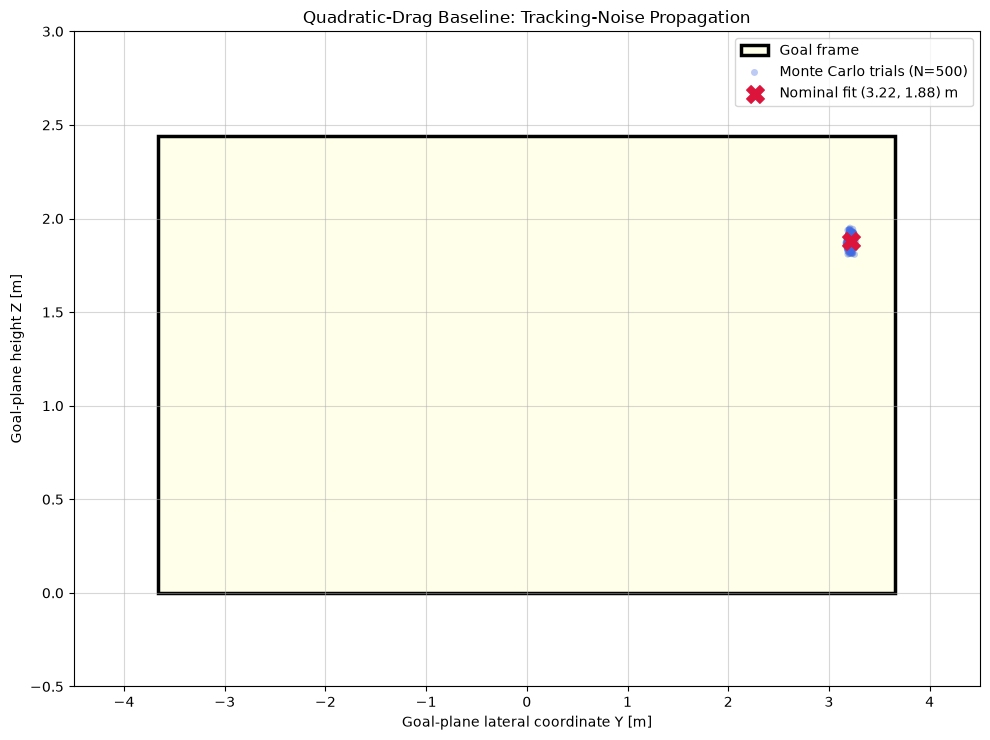

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.stats import chi2

# Constant-coefficient quadratic-drag baseline: a_drag = -q*|v|*v.
goal_x = 11.0
goal_y_bounds = (-3.66, 3.66)
goal_z_bounds = (0.0, 2.44)
g = 9.81
r0 = np.array([0.0, 0.0, 0.11])
r1 = np.array([1.50, 0.45, 0.44])
r2 = np.array([2.96, 0.86, 0.74])
dt = 0.05
observation_times = np.array([dt, 2 * dt])
sigma_position = 0.005  # Assumed independent Gaussian coordinate standard deviation (m)
n_trials = 500


def quadratic_drag_ode(t, state, q):
    x, y, z, vx, vy, vz = state
    velocity = np.array([vx, vy, vz])
    speed = np.linalg.norm(velocity)
    acceleration = -q * speed * velocity + np.array([0.0, 0.0, -g])
    return [vx, vy, vz, *acceleration]


def integrate_observations(v0, q):
    sol = solve_ivp(
        lambda t, state: quadratic_drag_ode(t, state, q),
        (0.0, observation_times[-1]), np.concatenate((r0, v0)),
        t_eval=observation_times, max_step=0.002, rtol=1e-8, atol=1e-10,
    )
    if not sol.success or sol.y.shape[1] != len(observation_times):
        raise RuntimeError(f"Observation integration failed: {sol.message}")
    return sol.y[:3, :].T


def fit_quadratic_drag(r1_observed, r2_observed):
    observed = np.vstack((r1_observed, r2_observed))
    v0_guess = (4 * r1_observed - r2_observed - 3 * r0) / (2 * dt)
    vx1 = (r1_observed[0] - r0[0]) / dt
    vx2 = (r2_observed[0] - r1_observed[0]) / dt
    path_length = 0.5 * (np.linalg.norm(r1_observed-r0) + np.linalg.norm(r2_observed-r1_observed))
    q_guess = np.log(vx1 / vx2) / path_length if vx1 > vx2 > 0 else 0.01
    q_guess = max(q_guess, 1e-5)

    def residual(parameters):
        return ((integrate_observations(parameters[:3], parameters[3]) - observed) / sigma_position).ravel()

    fit = least_squares(
        residual, np.concatenate((v0_guess, [q_guess])),
        bounds=(np.array([-np.inf, -np.inf, -np.inf, 1e-8]), np.full(4, np.inf)),
        x_scale="jac", max_nfev=100,
    )
    if not fit.success:
        raise RuntimeError(f"Quadratic-drag fit failed: {fit.message}")
    predicted = integrate_observations(fit.x[:3], fit.x[3])
    return fit.x[:3], fit.x[3], observed - predicted


def integrate_to_goal(v0, q):
    def goal_event(t, state):
        return state[0] - goal_x
    goal_event.terminal = True
    goal_event.direction = 1
    sol = solve_ivp(
        lambda t, state: quadratic_drag_ode(t, state, q),
        (0.0, 1.0), np.concatenate((r0, v0)), events=goal_event,
        max_step=0.002, rtol=1e-8, atol=1e-10,
    )
    if not sol.success:
        raise RuntimeError(f"Goal integration failed: {sol.message}")
    if len(sol.t_events[0]) == 0:
        raise RuntimeError("The fitted trajectory did not reach the goal plane.")
    return sol.t_events[0][0], sol.y_events[0][0]


# Fit all six measured coordinates with launch velocity and q as free parameters.
v0_fit, q_fit, fit_residuals = fit_quadratic_drag(r1, r2)
nominal_time, nominal_state = integrate_to_goal(v0_fit, q_fit)
fit_chi2 = np.sum((fit_residuals / sigma_position) ** 2)
fit_dof = fit_residuals.size - 4
print("CONSTANT-q QUADRATIC-DRAG BASELINE FIT")
print(f"Fitted launch velocity: {v0_fit.round(4)} m/s")
print(f"Fitted q: {q_fit:.6f} 1/m")
print(f"Observed - fitted position residuals (mm):\n{(1000 * fit_residuals).round(2)}")
print(f"Coordinate fit RMSE: {1000 * np.sqrt(np.mean(fit_residuals**2)):.2f} mm (assumed sigma = {1000*sigma_position:.1f} mm)")
print(f"Noise-only fit diagnostic: chi-square={fit_chi2:.2f}, dof={fit_dof}, p={chi2.sf(fit_chi2, fit_dof):.4f}")
print(f"Nominal goal crossing: t={nominal_time:.4f} s, y={nominal_state[1]:.3f} m, z={nominal_state[2]:.3f} m")

rng = np.random.default_rng(42)
flight_times, y_impacts, z_impacts = [], [], []
for _ in range(n_trials):
    r1_noisy = r1 + rng.normal(0.0, sigma_position, size=3)
    r2_noisy = r2 + rng.normal(0.0, sigma_position, size=3)
    v0_trial, q_trial, _ = fit_quadratic_drag(r1_noisy, r2_noisy)
    t_goal, impact_state = integrate_to_goal(v0_trial, q_trial)
    flight_times.append(t_goal)
    y_impacts.append(impact_state[1])
    z_impacts.append(impact_state[2])

flight_times = np.asarray(flight_times)
y_impacts = np.asarray(y_impacts)
z_impacts = np.asarray(z_impacts)
y_ci = np.percentile(y_impacts, [2.5, 97.5])
z_ci = np.percentile(z_impacts, [2.5, 97.5])
print(f"\n{n_trials}-TRIAL MEASUREMENT-NOISE PROPAGATION (sigma={1000*sigma_position:.1f} mm)")
print(f"Flight time mean +/- SD: {flight_times.mean():.4f} +/- {flight_times.std(ddof=1):.4f} s")
print(f"Mean impact coordinates: Y={y_impacts.mean():.3f} +/- {y_impacts.std(ddof=1):.3f} m; Z={z_impacts.mean():.3f} +/- {z_impacts.std(ddof=1):.3f} m")
print(f"Empirical 95% interval Y: [{y_ci[0]:.3f}, {y_ci[1]:.3f}] m")
print(f"Empirical 95% interval Z: [{z_ci[0]:.3f}, {z_ci[1]:.3f}] m")
print("Intervals are conditional on this constant-q model and assumed tracking noise, not real-world accuracy.")

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.add_patch(Rectangle((goal_y_bounds[0], goal_z_bounds[0]), goal_y_bounds[1]-goal_y_bounds[0], goal_z_bounds[1]-goal_z_bounds[0], facecolor="#FFFFEA", edgecolor="black", linewidth=2.5, label="Goal frame", zorder=1))
ax.scatter(y_impacts, z_impacts, color="#4169E1", alpha=0.35, edgecolors="none", s=25, label=f"Monte Carlo trials (N={n_trials})", zorder=2)
ax.scatter(nominal_state[1], nominal_state[2], color="#DC143C", marker="X", s=160, label=f"Nominal fit ({nominal_state[1]:.2f}, {nominal_state[2]:.2f}) m", zorder=3)
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-0.5, 3.0)
ax.set_xlabel("Goal-plane lateral coordinate Y [m]")
ax.set_ylabel("Goal-plane height Z [m]")
ax.set_title("Quadratic-Drag Baseline: Tracking-Noise Propagation")
ax.grid(True, alpha=0.5)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
